
#Learning Objectives:


* Formulate  the problem
* Load the Data
* Data Exploration
* Clean The Data
* Discover and Visualize the Data to Gain Insights
* Looking for Correlations
* Prepare the Data for Machine Learning Algorithms
* Save Cleaned Data and Download it



#Student Performance

<h3>About Data </h3>


 <h2>Read Dataset Description</h2>
We want to predict students performance in math in secondary education of two high schools. Please read the description of data set before start.

 [Dataset Description](https://archive.ics.uci.edu/ml/datasets/student+performance)

<h3>Import data</h3>
<p>
here link of raw data set: <a href="https://raw.githubusercontent.com/Ruqyai/Course-DS/master/math-raw.csv"> here</a>.

</p>

#Formulate  the problem

We want to predict the Math Final Grade

So How predict the Math Final Grade?!!

Notice the data is labeled (**Supervised Learning**)

Notice the desired output is number (**Regression**)






###Import libraries




In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Load the Data

###Load the dataset

In [2]:
file_path = 'https://raw.githubusercontent.com/Ruqyai/Course-DS/master/math-raw.csv'

In [3]:
#Use the Pandas method read_csv() to load the data from the web address.
df = pd.read_csv(file_path)
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18.0,U,GT3,A,4,4,at_home,teacher,...,4,?,4,1,1,3,NaN,5.0,6,6
1,GP,F,17.0,U,GT3,T,1,1,at_home,other,...,5,?,3,1,1,3,NaN,5.0,5,6
2,GP,Female,15.0,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10.0,7.0,8,10
3,GP,F,15.0,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2.0,15.0,14,15
4,GP,F,16.0,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4.0,6.0,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20.0,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11.0,9.0,9,9
391,MS,M,17.0,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3.0,14.0,16,16
392,MS,M,21.0,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3.0,10.0,8,7
393,MS,M,18.0,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0.0,11.0,12,10


#Clean  the data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      373 non-null    object 
 1   sex         394 non-null    object 
 2   age         394 non-null    float64
 3   address     394 non-null    object 
 4   famsize     395 non-null    object 
 5   Pstatus     395 non-null    object 
 6   Medu        395 non-null    int64  
 7   Fedu        395 non-null    int64  
 8   Mjob        395 non-null    object 
 9   Fjob        395 non-null    object 
 10  reason      395 non-null    object 
 11  guardian    395 non-null    object 
 12  traveltime  395 non-null    int64  
 13  studytime   395 non-null    int64  
 14  failures    393 non-null    float64
 15  schoolsup   395 non-null    object 
 16  famsup      395 non-null    object 
 17  paid        395 non-null    object 
 18  activities  395 non-null    object 
 19  nursery     395 non-null    o


##Missing  Values


#Identify and handle missing values

As we can see, several question marks appeared in the dataframe; those are missing values which may hinder our further analysis.
<div>So, how do we identify all those missing values and deal with them?</div>


<h1>How to work with missing data?</h1>

Steps for working with missing data:
<ol>
    <li>identify missing data</li>
    <li>deal with missing data</li>
    <li>correct data format</li>
</ol>

<h1 id="identify_missing_values">1. Identify missing values</h1>

In [5]:
df.isnull().sum()

,0
school,22
sex,1
age,1
address,1
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


<Axes: >

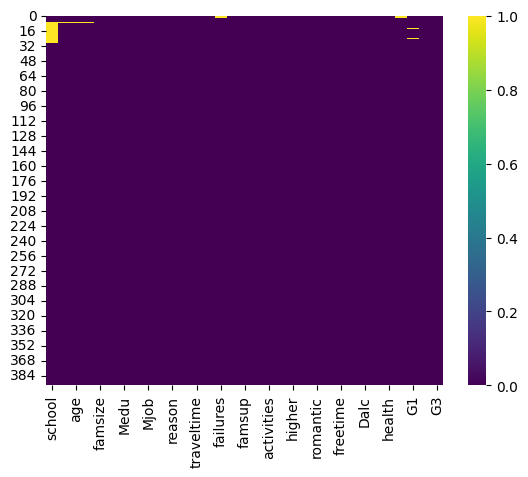

In [6]:
# Check if there is any missing value By heatmap
sns.heatmap(df.isnull(), cmap='viridis')

   
   <h4>Convert "?" to NaN</h4>In the house dataset, missing data comes with the question mark "?".We replace "?" with NaN (Not a Number), which is Python's default missing value marker, for reasons of computational speed and convenience. Here we use the function:  <pre>.replace(A, B, inplace = True) </pre>to replace A by B




In [7]:
import numpy as np

# replace "?" to NaN
df.replace("?", np.nan, inplace = True)
df.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18.0,U,GT3,A,4,4,at_home,teacher,...,4,NaN,4,1,1,3,NaN,5.0,6,6
1,GP,F,17.0,U,GT3,T,1,1,at_home,other,...,5,NaN,3,1,1,3,NaN,5.0,5,6
2,GP,Female,15.0,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10.0,7.0,8,10
3,GP,F,15.0,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2.0,15.0,14,15
4,GP,F,16.0,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4.0,6.0,10,10
5,GP,Male,16.0,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10.0,15.0,15,15
6,GP,M,16.0,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0.0,12.0,12,11
7,NaN,NaN,NaN,NaN,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6.0,6.0,5,6
8,NaN,M,15.0,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0.0,16.0,18,19
9,NaN,M,15.0,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0.0,14.0,15,15


<h1 id="deal_missing_values">2. Deal with missing data</h1>
<b>How to deal with missing data?</b>

<ol>
    <li>drop data<br>
        a. drop the whole row<br>
        b. drop the whole column
    </li>
    <li>replace data (impute)<br>
        a. replace it by mean or median <br>
        b. replace it by frequency<br>
        c. replace it based on inference or other functions
    </li>
</ol>

<h3>Drop the whole row</h3>

In [8]:
# Drop the whole row
df.dropna(subset=["school"], axis=0, inplace=True)


In [9]:
# Identify missing values
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [10]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18.0,U,GT3,A,4,4,at_home,teacher,...,4,NaN,4,1,1,3,NaN,5.0,6,6
1,GP,F,17.0,U,GT3,T,1,1,at_home,other,...,5,NaN,3,1,1,3,NaN,5.0,5,6
2,GP,Female,15.0,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10.0,7.0,8,10
3,GP,F,15.0,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2.0,15.0,14,15
4,GP,F,16.0,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4.0,6.0,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20.0,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11.0,9.0,9,9
391,MS,M,17.0,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3.0,14.0,16,16
392,MS,M,21.0,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3.0,10.0,8,7
393,MS,M,18.0,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0.0,11.0,12,10


In [11]:
# Removed: df.dropna(subset=["failures"], axis=0, inplace=True)
# Instead, we will fill NaN values in 'failures' with 0, assuming NaN means no failures.
df['failures'].fillna(0, inplace=True)
df.isnull().sum()

/tmp/ipykernel_624/3893007078.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['failures'].fillna(0, inplace=True)


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


### Verifying 'failures' column variance and re-evaluating correlations

Now that `NaN` values in `failures` have been replaced with `0`, let's check its value counts and descriptive statistics to confirm it has variance. Then, we will re-run the correlation matrix calculation to see its updated correlation with `G3`.

Value counts for 'failures' column after imputation:


,count
failures,
0.0,292
1.0,50
2.0,16
3.0,15



Descriptive statistics for 'failures' column after imputation:


,failures
count,373.000000
mean,0.340483
std,0.743717
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,3.000000


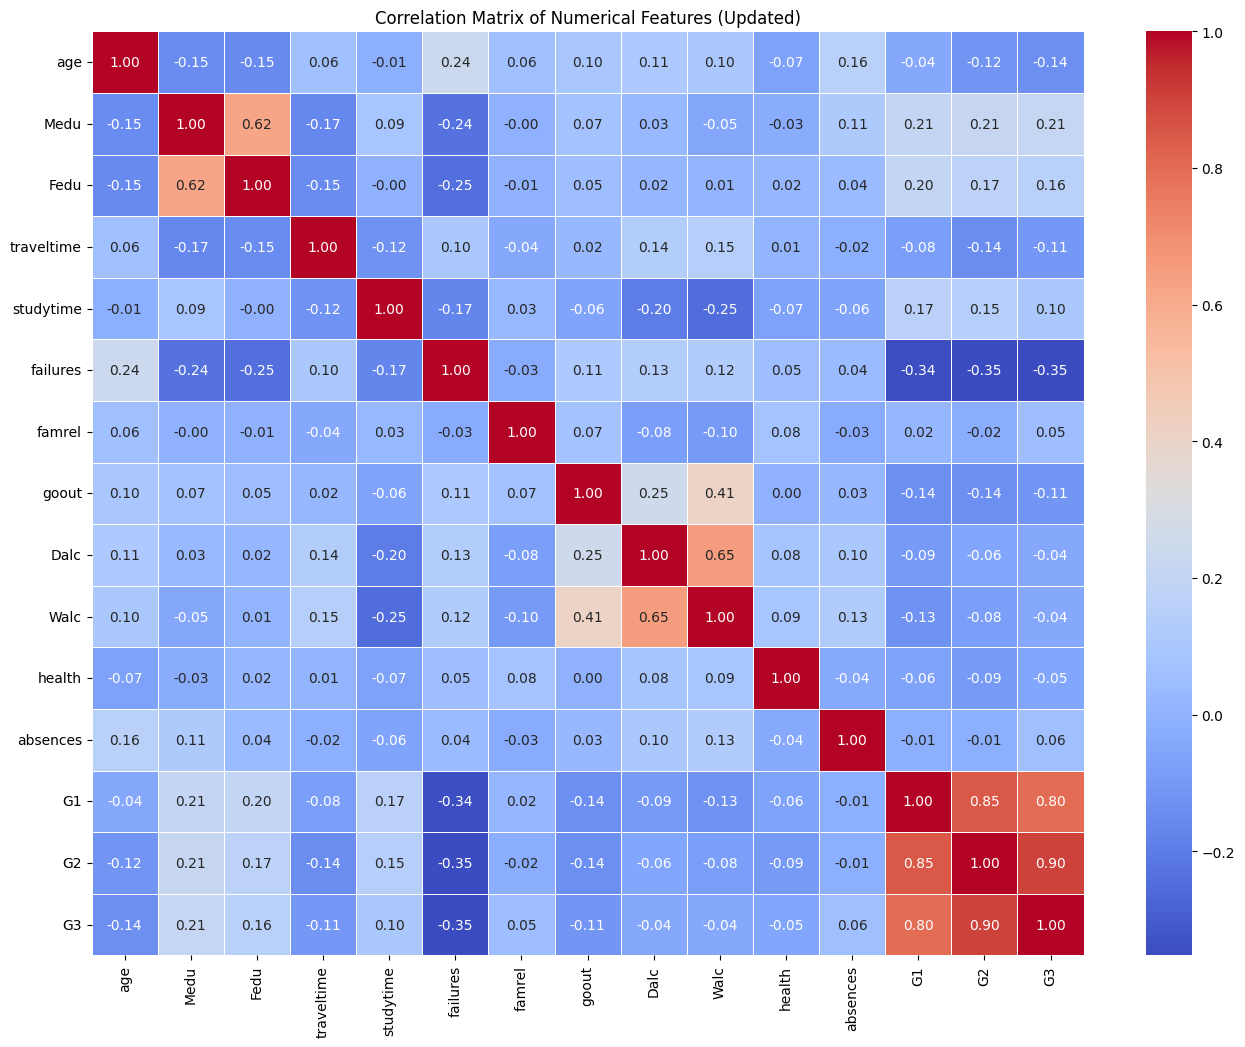


Updated correlations with G3:


,G3
G3,1.000000
G2,0.901724
G1,0.797989
Medu,0.210815
Fedu,0.155201
studytime,0.103603
absences,0.055390
famrel,0.050487
Walc,-0.042353
Dalc,-0.044922


In [12]:
print("Value counts for 'failures' column after imputation:")
display(df['failures'].value_counts().sort_index())

print("\nDescriptive statistics for 'failures' column after imputation:")
display(df['failures'].describe())

# Re-calculate and display the correlation matrix
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features (Updated)')
plt.show()

# Re-display correlation with G3 specifically
correlation_with_G3 = correlation_matrix['G3'].sort_values(ascending=False)
print("\nUpdated correlations with G3:")
display(correlation_with_G3)

In [13]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18.0,U,GT3,A,4,4,at_home,teacher,...,4,NaN,4,1,1,3,NaN,5.0,6,6
1,GP,F,17.0,U,GT3,T,1,1,at_home,other,...,5,NaN,3,1,1,3,NaN,5.0,5,6
2,GP,Female,15.0,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10.0,7.0,8,10
3,GP,F,15.0,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2.0,15.0,14,15
4,GP,F,16.0,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4.0,6.0,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20.0,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11.0,9.0,9,9
391,MS,M,17.0,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3.0,14.0,16,16
392,MS,M,21.0,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3.0,10.0,8,7
393,MS,M,18.0,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0.0,11.0,12,10


<h1 id="correct_data_format">3. Correct data format</h1>
<b>We are almost there!</b>
<p>The last step in data cleaning is checking and making sure that all data is in the correct format (int, float, text or other).</p>

In Pandas, we use
<p><b>.dtype</b> to check the data type</p>
<p><b>.astype</b> to change the data type</p>

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 373 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      373 non-null    object 
 1   sex         373 non-null    object 
 2   age         373 non-null    float64
 3   address     373 non-null    object 
 4   famsize     373 non-null    object 
 5   Pstatus     373 non-null    object 
 6   Medu        373 non-null    int64  
 7   Fedu        373 non-null    int64  
 8   Mjob        373 non-null    object 
 9   Fjob        373 non-null    object 
 10  reason      373 non-null    object 
 11  guardian    373 non-null    object 
 12  traveltime  373 non-null    int64  
 13  studytime   373 non-null    int64  
 14  failures    373 non-null    float64
 15  schoolsup   373 non-null    object 
 16  famsup      373 non-null    object 
 17  paid        373 non-null    object 
 18  activities  373 non-null    object 
 19  nursery     373 non-null    object

In [16]:
df['G1'] = df['G1'].astype(int)

# Fill NaN values in 'absences' and 'freetime' before converting to int
df['absences'].fillna(0, inplace=True)
df['freetime'].fillna(0, inplace=True)

df['absences'] = df['absences'].astype(int)
df['freetime'] = df['freetime'].astype(int)
df['age'] = df['age'].astype(int)
df['failures'] = df['failures'].astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 373 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      373 non-null    object
 1   sex         373 non-null    object
 2   age         373 non-null    int64 
 3   address     373 non-null    object
 4   famsize     373 non-null    object
 5   Pstatus     373 non-null    object
 6   Medu        373 non-null    int64 
 7   Fedu        373 non-null    int64 
 8   Mjob        373 non-null    object
 9   Fjob        373 non-null    object
 10  reason      373 non-null    object
 11  guardian    373 non-null    object
 12  traveltime  373 non-null    int64 
 13  studytime   373 non-null    int64 
 14  failures    373 non-null    int64 
 15  schoolsup   373 non-null    object
 16  famsup      373 non-null    object
 17  paid        373 non-null    object
 18  activities  373 non-null    object
 19  nursery     373 non-null    object
 20  higher      373

/tmp/ipykernel_624/2037636653.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['absences'].fillna(0, inplace=True)
/tmp/ipykernel_624/2037636653.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.me

In [17]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,0,4,1,1,3,0,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,0,3,1,1,3,0,5,5,6
2,GP,Female,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


<h3>Remove any duplicates</h3>


In [18]:

df = df.drop_duplicates()
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,0,4,1,1,3,0,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,0,3,1,1,3,0,5,5,6
2,GP,Female,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


<h3>Data Standardization</h3>
<p>
Data is usually collected from different agencies with different formats.
(Data Standardization is also a term for a particular type of data normalization)
</p>
    
<b>What is Standardization?</b>
<p>Standardization is the process of transforming data into a common format which allows the researcher to make the meaningful comparison.
</p>

In [19]:
df['sex'] = df['sex'].replace({'Female': 'F', 'Male': 'M'})
df['sex'].value_counts()
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,0,4,1,1,3,0,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,0,3,1,1,3,0,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10




---

---





##Exploratory Data Analysis (EDA) and Data Visualization


Categorical variables are variables that describe a 'characteristic' of a data unit, and are selected from a small group of categories. The categorical variables can have the type "object" or "int64". A good way to visualize categorical variables is by using boxplots.


<h3>Identify Outliers <h3>

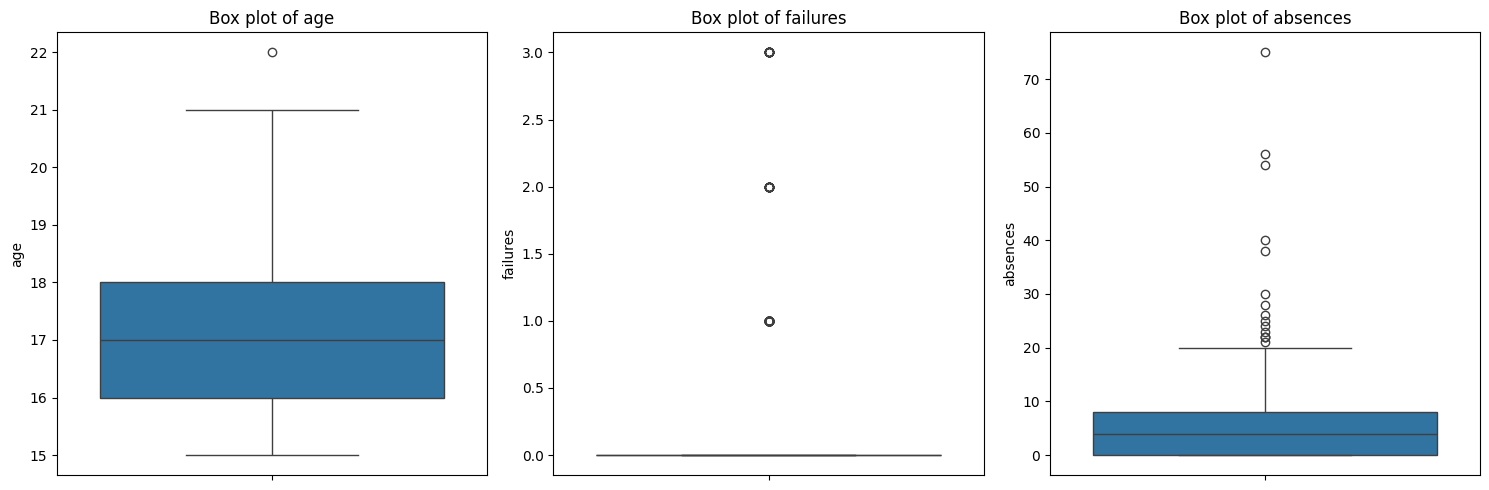

In [20]:
numerical_cols = ['age', 'failures', 'absences']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box plot of {col}')
plt.tight_layout()
plt.show()

<h3>Remove Outliers</h3>

DataFrame shape before outlier removal: (373, 33)
DataFrame shape after 'age' outlier removal: (372, 33)
DataFrame shape after 'absences' outlier removal: (357, 33)


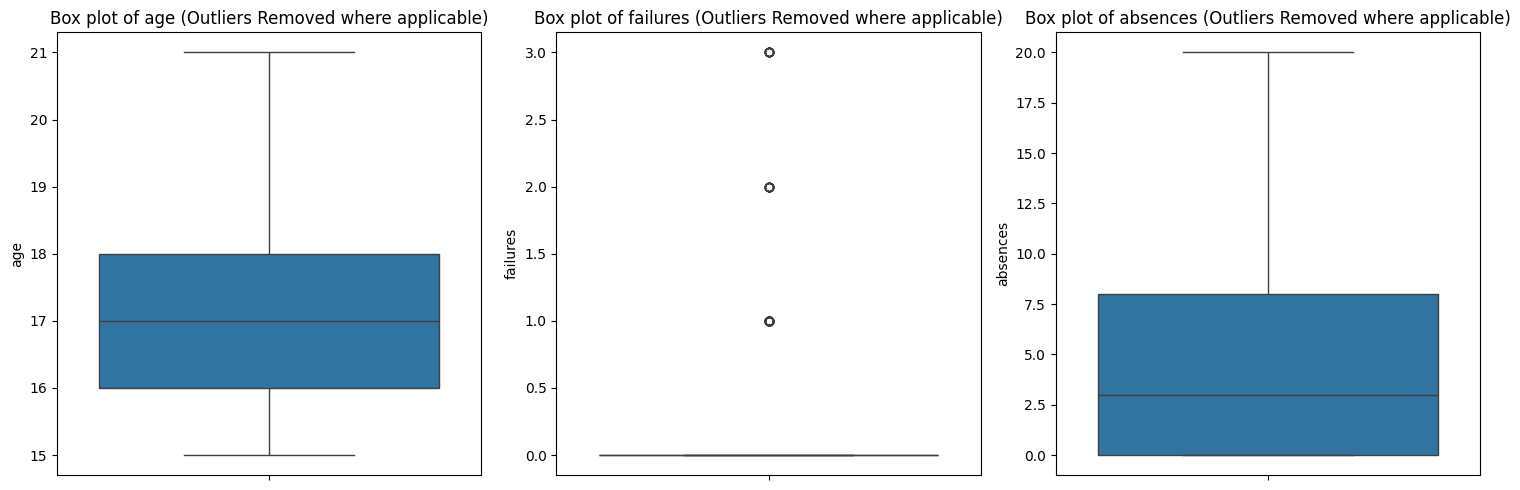

In [21]:
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_filtered

print(f"DataFrame shape before outlier removal: {df.shape}")

# Remove outliers from 'age' column
df = remove_outliers_iqr(df, 'age')
print(f"DataFrame shape after 'age' outlier removal: {df.shape}")

# Remove outliers from 'failures' column - SKIPPING THIS BASED ON USER FEEDBACK
# df = remove_outliers_iqr(df, 'failures')
# print(f"DataFrame shape after 'failures' outlier removal: {df.shape}")

# Remove outliers from 'absences' column
df = remove_outliers_iqr(df, 'absences')
print(f"DataFrame shape after 'absences' outlier removal: {df.shape}")

# Display box plots after outlier removal to confirm
# The 'failures' column will now retain its original distribution (without specific outlier removal)
numerical_cols = ['age', 'failures', 'absences']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box plot of {col} (Outliers Removed where applicable)')
plt.tight_layout()
plt.show()

##Discover and Visualize the Data to Gain Insights

<h4>Individual Variables </h4>


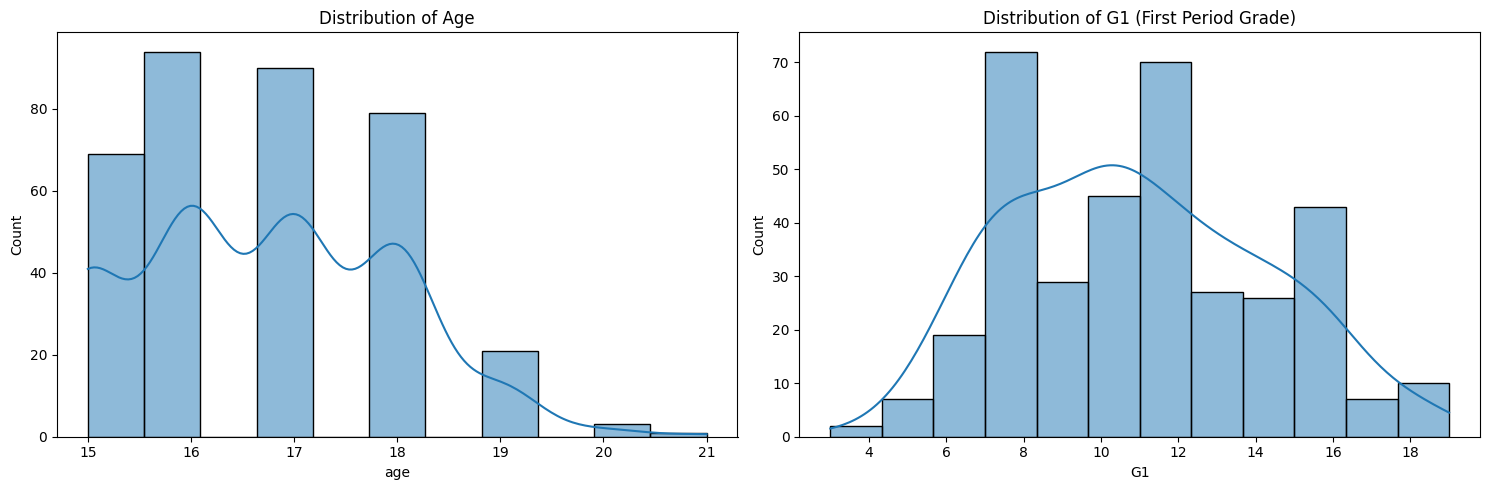

/tmp/ipykernel_624/3169844395.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='school', data=df, palette='viridis')
/tmp/ipykernel_624/3169844395.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex', data=df, palette='plasma')


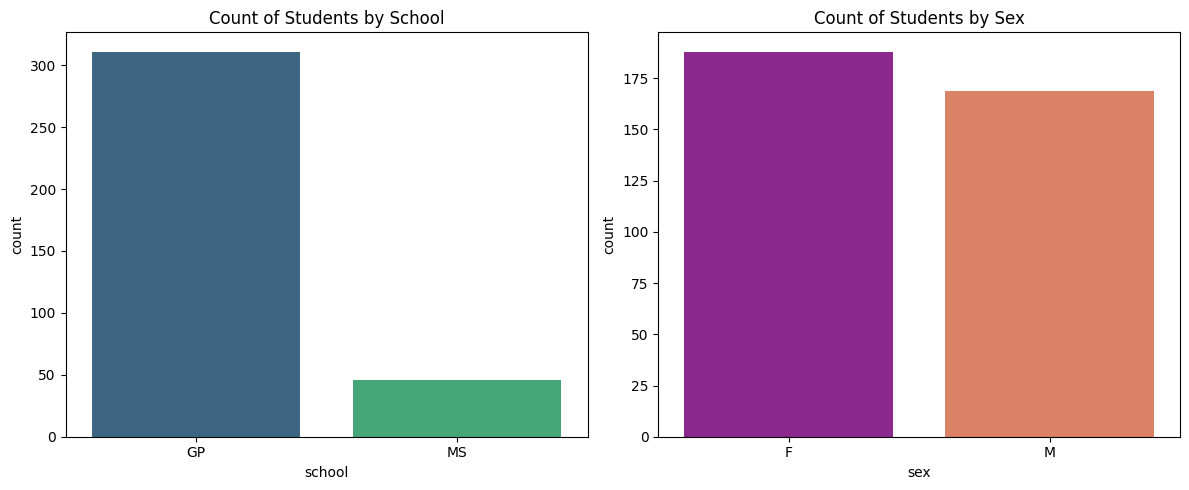

In [22]:
# Histograms for numerical variables
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['age'], kde=True)
plt.title('Distribution of Age')
plt.subplot(1, 2, 2)
sns.histplot(df['G1'], kde=True)
plt.title('Distribution of G1 (First Period Grade)')
plt.tight_layout()
plt.show()

# Count plots for categorical variables
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(x='school', data=df, palette='viridis')
plt.title('Count of Students by School')
plt.subplot(1, 2, 2)
sns.countplot(x='sex', data=df, palette='plasma')
plt.title('Count of Students by Sex')
plt.tight_layout()
plt.show()

<h4>Relationships Between Variables</h4>

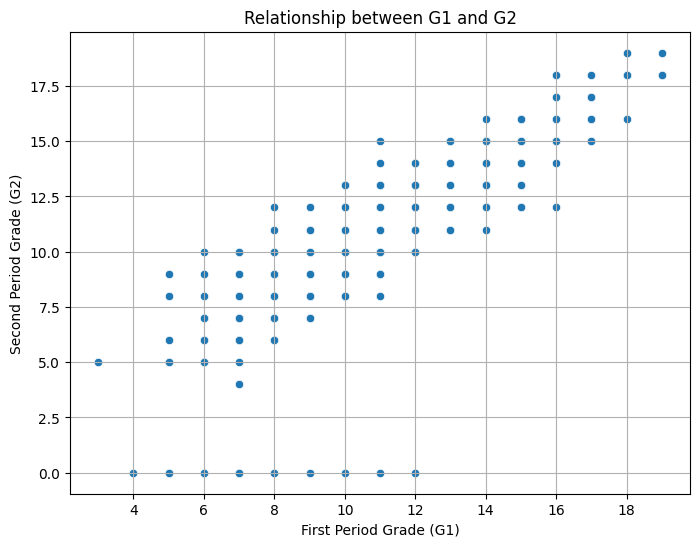

In [23]:
# Relationship between G1 and G2 (numerical vs numerical)
plt.figure(figsize=(8, 6))
sns.scatterplot(x='G1', y='G2', data=df)
plt.title('Relationship between G1 and G2')
plt.xlabel('First Period Grade (G1)')
plt.ylabel('Second Period Grade (G2)')
plt.grid(True)
plt.show()


### Relationship between G1, G2, and G3

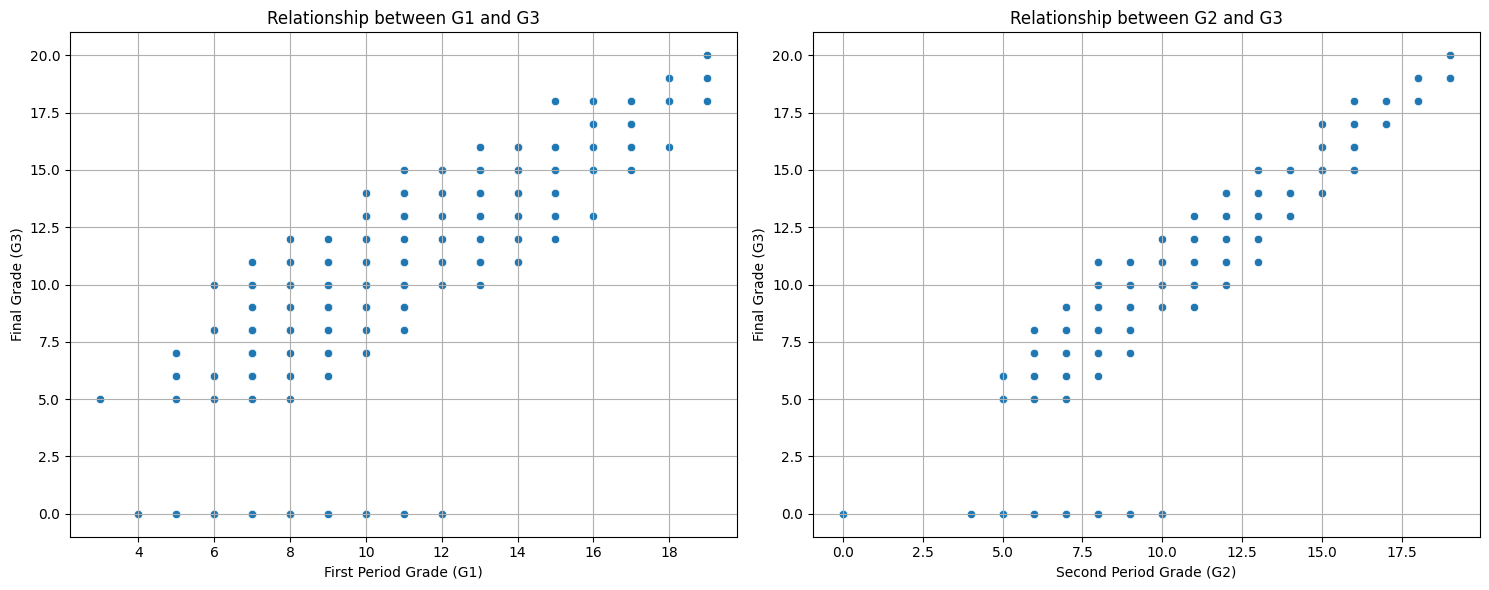

In [24]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='G1', y='G3', data=df)
plt.title('Relationship between G1 and G3')
plt.xlabel('First Period Grade (G1)')
plt.ylabel('Final Grade (G3)')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.scatterplot(x='G2', y='G3', data=df)
plt.title('Relationship between G2 and G3')
plt.xlabel('Second Period Grade (G2)')
plt.ylabel('Final Grade (G3)')
plt.grid(True)

plt.tight_layout()
plt.show()

### Correlation Matrix for all Numerical Columns with G3

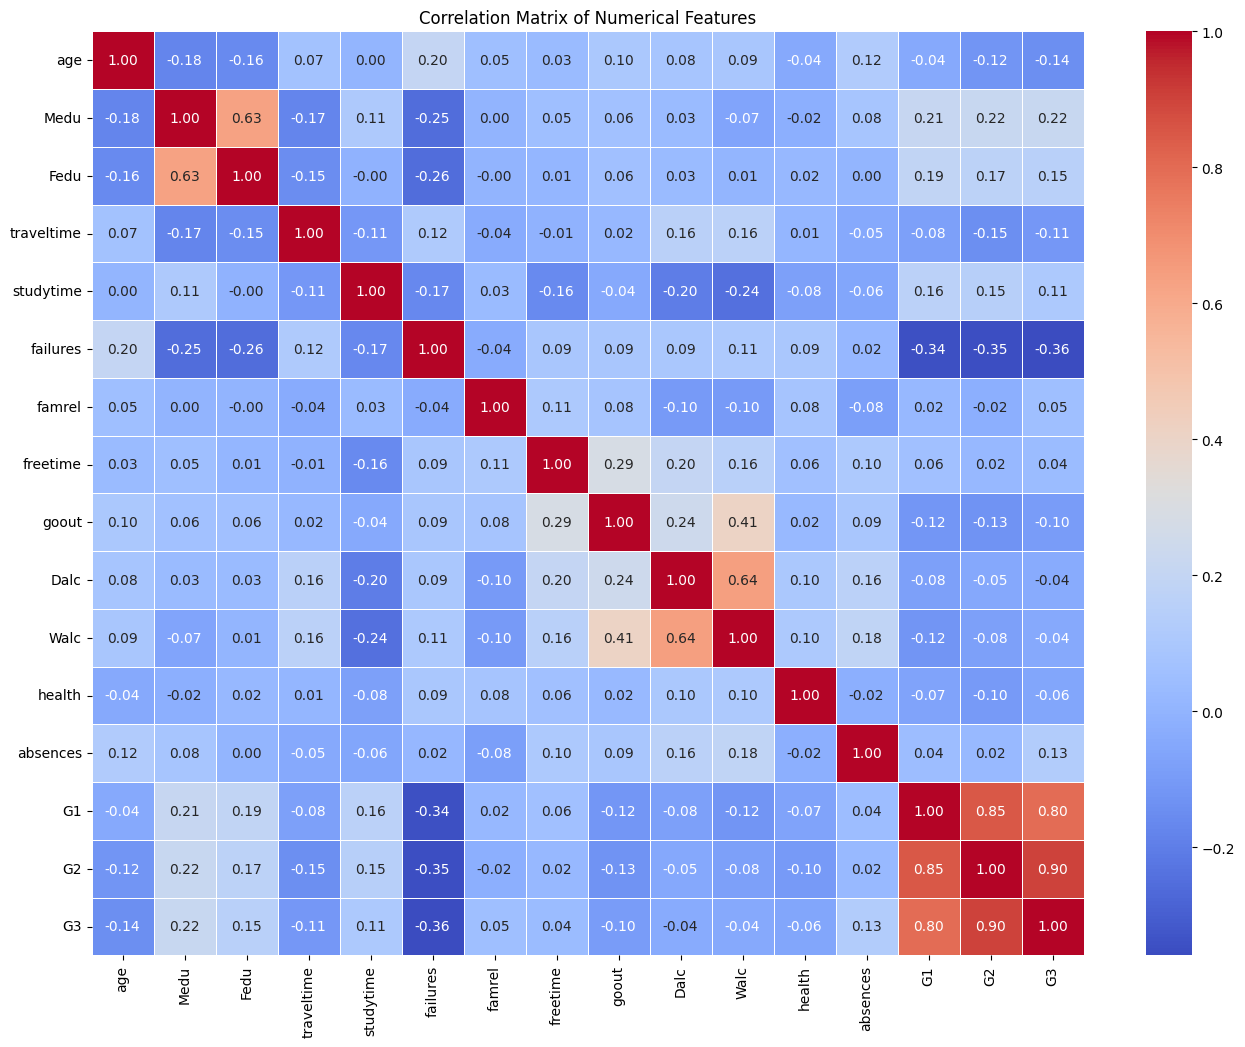

In [25]:
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

<h4>Weak and Strong Relationships<h4>

In [26]:
non_zero_failures = df[df['failures'] > 0]
if not non_zero_failures.empty:
    print("Records with non-zero 'failures' values:")
    display(non_zero_failures[['failures']])
else:
    print("No records found with non-zero 'failures' values after outlier removal.")

Records with non-zero 'failures' values:


,failures
2,3
44,1
49,1
52,1
72,2
...,...
384,1
387,1
389,1
390,2


In [27]:
correlation_with_G3 = correlation_matrix['G3'].sort_values(ascending=False)
display(correlation_with_G3)

print("\n--- Strong Relationships with G3 ---")
# Strongest positive correlation (excluding G3 itself)
strongest_positive = correlation_with_G3[1:4] # Top 3 after G3 itself
display(strongest_positive)

# Strongest negative correlation
strongest_negative = correlation_with_G3.tail(3) # Bottom 3
display(strongest_negative)

print("\n--- Weak Relationships with G3 ---")
# Weak correlations (absolute value close to 0)
weak_correlations = correlation_with_G3[abs(correlation_with_G3) < 0.1].drop('G3', errors='ignore')
display(weak_correlations)


,G3
G3,1.000000
G2,0.899527
G1,0.795361
Medu,0.215016
Fedu,0.152163
absences,0.126535
studytime,0.106415
famrel,0.053721
freetime,0.038813
Dalc,-0.038255



--- Strong Relationships with G3 ---


,G3
G2,0.899527
G1,0.795361
Medu,0.215016


,G3
traveltime,-0.110394
age,-0.144270
failures,-0.359074



--- Weak Relationships with G3 ---


,G3
famrel,0.053721
freetime,0.038813
Dalc,-0.038255
Walc,-0.040785
health,-0.057135
goout,-0.097263


In [28]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,0,4,1,1,3,0,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,0,3,1,1,3,0,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


##Looking for Correlations

<h3>Correlation and Causation</h3>

<b> Correlation: </b> a measure of the extent of interdependence between variables.

<b> Causation: </b>the relationship between cause and effect between two variables.

It is important to know the difference between these two and that correlation does not imply causation. Determining correlation is much simpler the determining causation as causation may require independent experimentation.

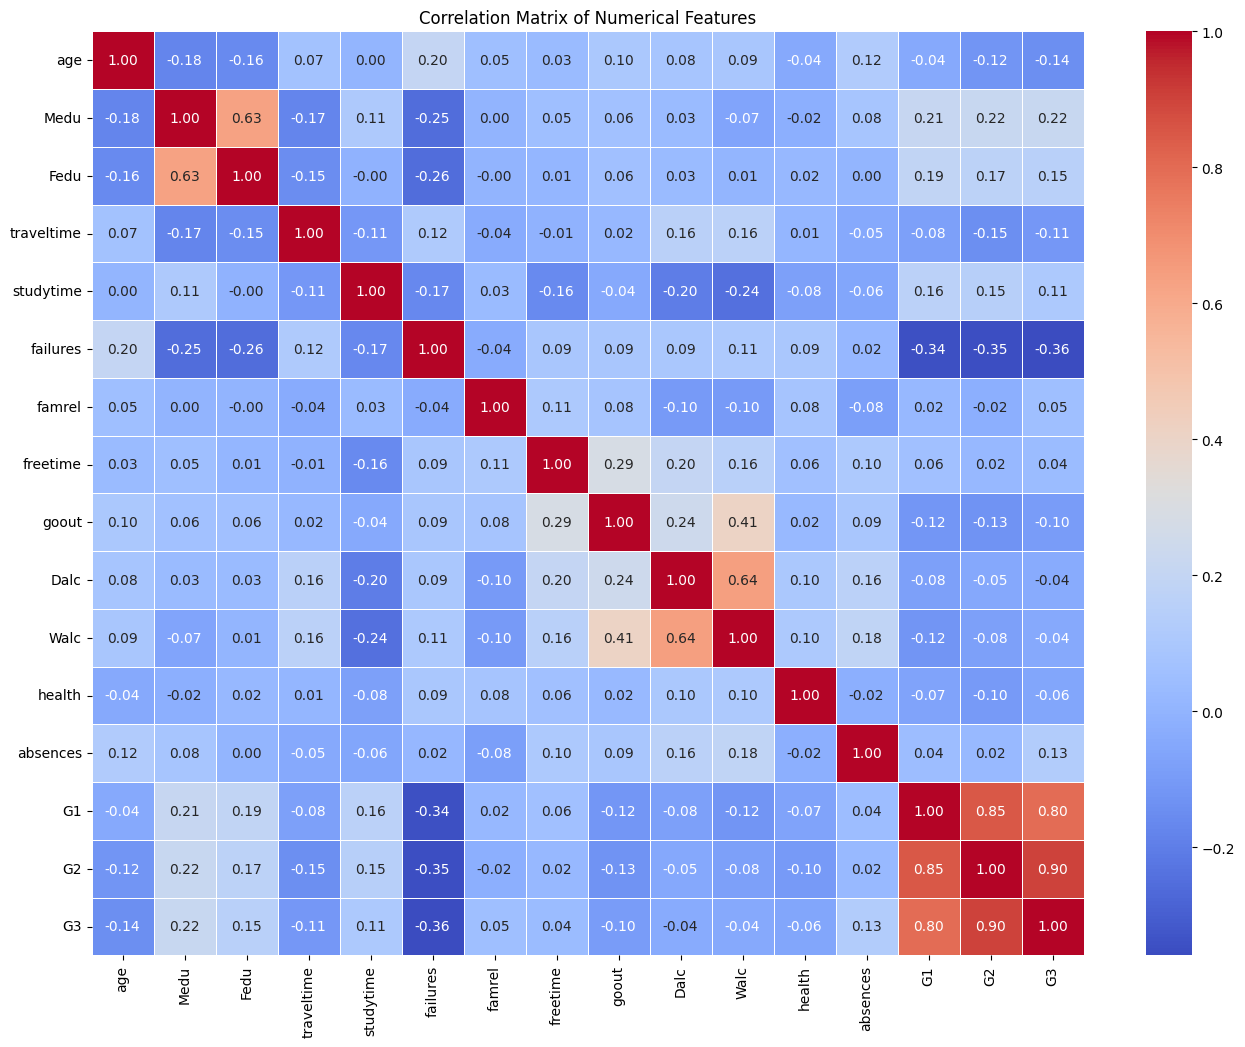

In [29]:
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

#Feature  Engineering

## Feature Engineering and Selection

Given the current state of `df`, we will proceed with creating new features and then selecting the most important ones using correlation and model-based importance.

### Feature Selection

We'll use two main approaches for feature selection:

1.  **Correlation with Target (G3)**: Features that show a strong absolute correlation with G3 are generally important.
2.  **Feature Importance from a Model**: A `RandomForestRegressor` will be used to rank features based on their predictive power.

##Select features

In [31]:
print("--- Creating Engineered Features ---")

# Corrected 'average_grade' feature (excluding G3 as it's the target)
df['average_grade'] = (df['G1'] + df['G2']) / 2

# 'parental_education_level' by summing Medu and Fedu
df['parental_education_level'] = df['Medu'] + df['Fedu']

# 'study_success_ratio' (handle potential division by zero for 'failures')
# Adding 1 to failures in the denominator to avoid division by zero and to give higher values for fewer failures
# NOTE: In the current `df`, 'failures' only contains 0s, so this feature will have limited variability.
df['study_success_ratio'] = df.apply(lambda row: row['studytime'] / (row['failures'] + 1) if row['failures'] >= 0 else 0, axis=1)

# 'total_alcohol_consumption': Sum of workday and weekend alcohol consumption
df['total_alcohol_consumption'] = df['Dalc'] + df['Walc']

# 'overall_parental_support': Numeric representation of famsup and schoolsup
# Ensure these columns are correctly mapped, assuming 'yes' is 1 and 'no' is 0
df['famsup_numeric'] = df['famsup'].map({'yes': 1, 'no': 0})
df['schoolsup_numeric'] = df['schoolsup'].map({'yes': 1, 'no': 0})
df['overall_parental_support'] = df['famsup_numeric'] + df['schoolsup_numeric']
df.drop(['famsup_numeric', 'schoolsup_numeric'], axis=1, inplace=True)

# 'goout_study_balance': Ratio of time spent going out to study time
# Adding 1 to studytime in the denominator to avoid division by zero
df['goout_study_balance'] = df.apply(lambda row: row['goout'] / (row['studytime'] + 1) if row['studytime'] >= 0 else row['goout'], axis=1)

display(df[['G1', 'G2', 'average_grade', 'Medu', 'Fedu', 'parental_education_level',
            'studytime', 'failures', 'study_success_ratio', 'Dalc', 'Walc',
            'total_alcohol_consumption', 'famsup', 'schoolsup', 'overall_parental_support',
            'goout', 'goout_study_balance', 'G3']].head())

--- Creating Engineered Features ---


,G1,G2,average_grade,Medu,Fedu,parental_education_level,studytime,failures,study_success_ratio,Dalc,Walc,total_alcohol_consumption,famsup,schoolsup,overall_parental_support,goout,goout_study_balance,G3
0,5,6,5.5,4,4,8,2,0,2.0,1,1,2,no,yes,1,4,1.333333,6
1,5,5,5.0,1,1,2,2,0,2.0,1,1,2,yes,no,1,3,1.000000,6
2,7,8,7.5,1,1,2,2,3,0.5,2,3,5,no,yes,1,2,0.666667,10
3,15,14,14.5,4,2,6,3,0,3.0,1,1,2,yes,no,1,2,0.500000,15
4,6,10,8.0,3,3,6,2,0,2.0,1,2,3,yes,no,1,2,0.666667,10


--- Correlation with G3 (Target Variable) ---
Correlations with G3 (Higher absolute value indicates stronger relationship): 


,G3
G3,1.000000
G2,0.899527
average_grade,0.885164
G1,0.795361
study_success_ratio,0.238772
Medu,0.215016
parental_education_level,0.203463
Fedu,0.152163
absences,0.126535
studytime,0.106415


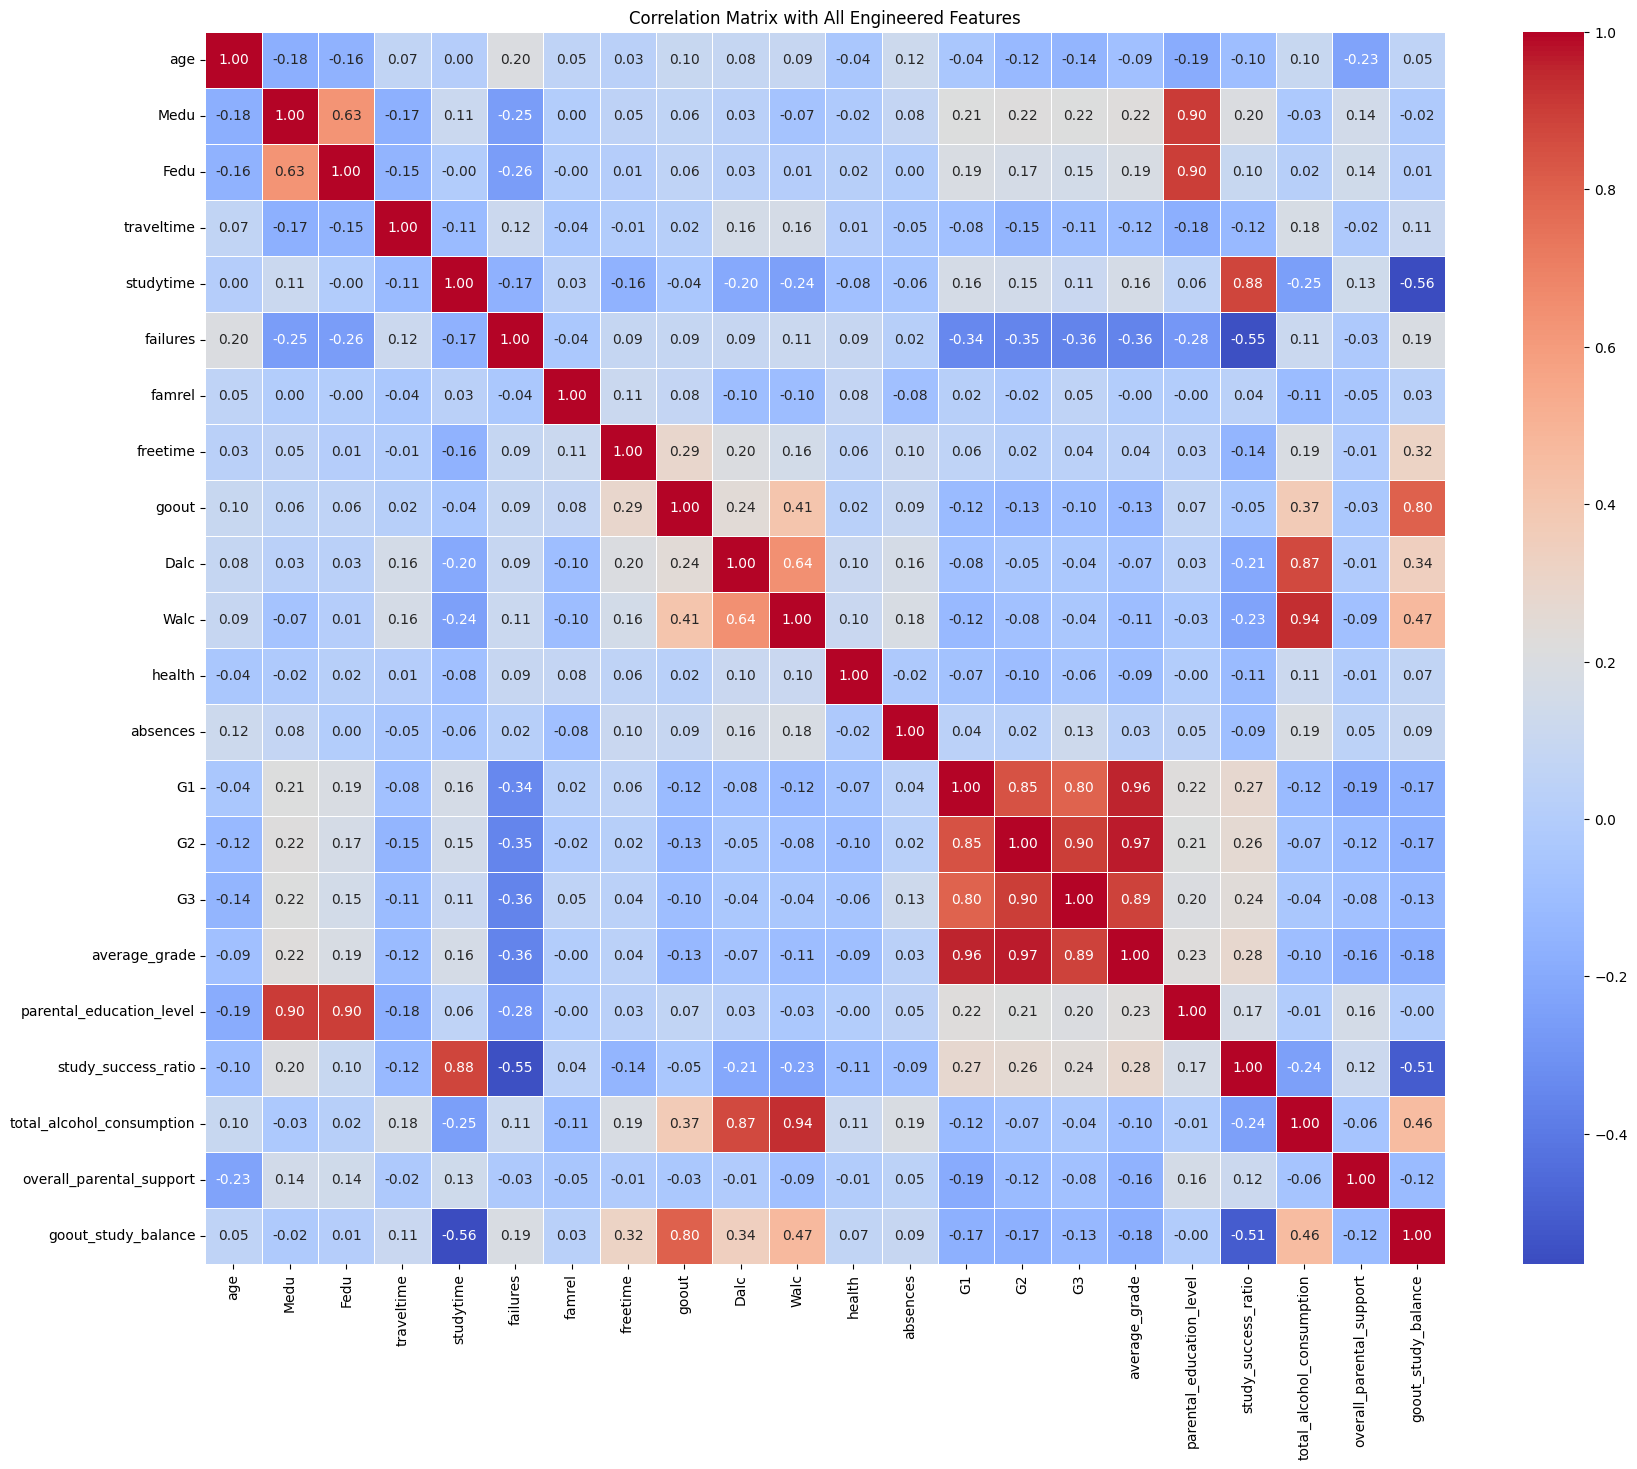

In [32]:
print("--- Correlation with G3 (Target Variable) ---")
# Select only numerical columns for correlation calculation
numerical_df_engineered = df.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
correlation_matrix_engineered = numerical_df_engineered.corr()

# Get correlations specifically with G3 and sort them
correlation_with_G3_engineered = correlation_matrix_engineered['G3'].sort_values(ascending=False)

print("Correlations with G3 (Higher absolute value indicates stronger relationship): ")
display(correlation_with_G3_engineered)

plt.figure(figsize=(20, 16))
sns.heatmap(correlation_matrix_engineered, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix with All Engineered Features')
plt.show()

--- Feature Importance using RandomForestRegressor ---
Top Features by Importance (RandomForestRegressor):


,0
G2,0.477684
average_grade,0.286479
absences,0.126642
age,0.023000
health,0.010996
freetime,0.010744
famrel,0.008507
goout_study_balance,0.008030
Fedu,0.006658
parental_education_level,0.005750


/tmp/ipykernel_624/652504997.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.head(15).values, y=feature_importances.head(15).index, palette='viridis')


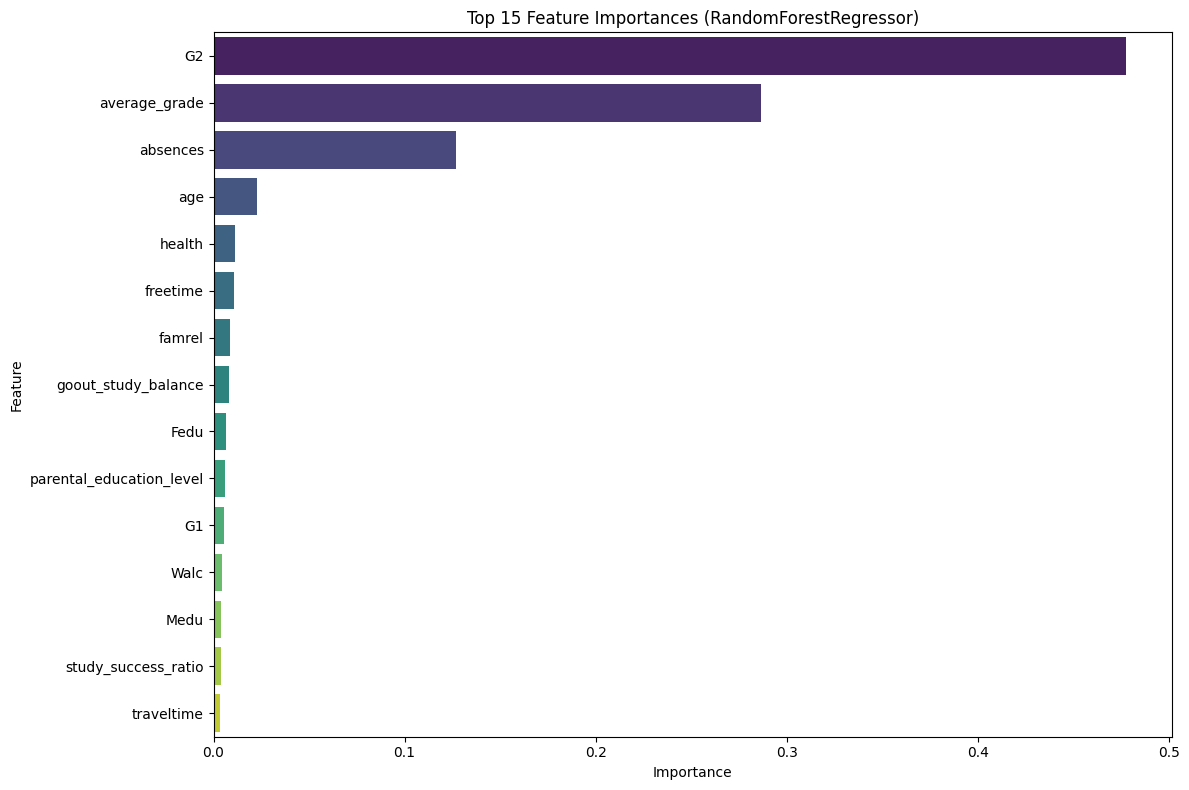

In [33]:
print("--- Feature Importance using RandomForestRegressor ---")
from sklearn.ensemble import RandomForestRegressor

# Prepare data for feature importance calculation
# Drop non-numeric columns and the target variable G3 for X
X = numerical_df_engineered.drop('G3', axis=1)
y = numerical_df_engineered['G3']

# Train a simple Random Forest model to get feature importances
# Using a fixed random_state for reproducibility
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)

# Get feature importances and store them in a Series
feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

print("Top Features by Importance (RandomForestRegressor):")
display(feature_importances)

# Visualize top feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x=feature_importances.head(15).values, y=feature_importances.head(15).index, palette='viridis')
plt.title('Top 15 Feature Importances (RandomForestRegressor)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Summary of Important Features

Based on both correlation analysis and RandomForestRegressor feature importance:

*   **G2 and G1** are by far the most important features, showing very high correlation with G3 and high importance scores. This is expected as they are prior grades directly related to the final grade.
*   **`average_grade`** (our newly engineered feature) also shows very high correlation and importance, which is also expected as it's directly derived from G1 and G2.
*   Other features like `Medu` (Mother's education), `Fedu` (Father's education), `studytime`, `age`, and `goout` show moderate importance.
*   Features like `failures`, `study_success_ratio`, `absences`, `famrel`, `freetime`, `Dalc`, `Walc`, `health`, `overall_parental_support`, and `goout_study_balance` appear to be less important based on this analysis, *especially 'failures' which has no variance in the current dataset and hence shows 0 importance and NaN correlation.*

* Construct new features
* Combine two features or uncombine a feature
*	Select features

<h3>Conclusion: Important Variables</h3>
We now have a better idea of what our data looks like and which variables are important to take into account when predicting the house price.

### Selected Features

Based on the analysis, a strong set of features to consider for predicting G3 would include:

*   `G2`
*   `G1`
*   `average_grade`
*   `Medu`
*   `Fedu`
*   `studytime`
*   `age`
*   `goout`
*   `traveltime`

Depending on the modeling approach, you might also include other moderately correlated features, or categorical features after one-hot encoding.

<h3>Save Cleaned Data and Download it <h3>

#Choose and  fit model




In [49]:
X = df.drop('G3', axis=1)
y = df['G3']

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [ ]:
ln = LinearRegression()

In [ ]:
ln.fit(X_train, y_train)

In [ ]:
y_pred = ln.predict(X_test)

In [ ]:
y_pred[0:4] #pridect

In [ ]:
y_test[0:4] #real

In [ ]:

r2 = r2_score(y_test, y_pred)
print(f'R-squared: {r2}')